In [ ]:

import pandas as pd
import sqlite3

print("Week 3 SQL Dashboard - Setup Ready!")

Week 3 SQL Dashboard - Setup Ready!


In [ ]:
import pandas as pd
import sqlite3

# Create mock applicants
applicants = pd.DataFrame({
    "applicant_id": range(1, 21),
    "name": [f"Applicant_{i}" for i in range(1, 21)],
    "domain": [
        "Data Science", "Web Development", "Cyber Security",
        "App Development", "UI/UX Design"
    ] * 4,
    "university": [
        "ABC University", "XYZ University",
        "City University", "Tech University"
    ] * 5,
    "application_date": ["2026-01-10"] * 20,
    "status": [
        "Selected", "Selected", "Rejected", "Under Review",
        "Selected", "Rejected", "Selected", "Selected",
        "Rejected", "Selected", "Under Review", "Selected",
        "Rejected", "Selected", "Selected", "Rejected",
        "Selected", "Under Review", "Rejected", "Selected"
    ]
})

# Create mock interns
interns = pd.DataFrame({
    "intern_id": range(101, 111),
    "applicant_id": [1, 2, 5, 7, 8, 10, 12, 14, 15, 17],
    "domain": [
        "Data Science", "Web Development", "Data Science",
        "App Development", "UI/UX Design", "Web Development",
        "Cyber Security", "UI/UX Design", "Data Science",
        "App Development"
    ],
    "start_date": ["2026-02-01"] * 10,
    "completion_status": [
        "Completed", "Completed", "Completed", "Dropped Out",
        "Completed", "Completed", "Completed", "Completed",
        "Dropped Out", "Completed"
    ]
})

# Create mock hackathon scores
hackathon_scores = pd.DataFrame({
    "intern_id": range(101, 111),
    "score": [92, 88, 95, 70, 86, 81, 90, 89, 65, 94],
    "domain": interns["domain"]
})

# Create SQLite database
conn = sqlite3.connect("nextgen.db")

applicants.to_sql("applicants", conn, if_exists="replace", index=False)
interns.to_sql("interns", conn, if_exists="replace", index=False)
hackathon_scores.to_sql(
    "hackathon_scores", conn, if_exists="replace", index=False
)

print("Mock dataset created successfully!")
print("Applicants:", len(applicants))
print("Interns:", len(interns))
print("Hackathon scores:", len(hackathon_scores))

Mock dataset created successfully!
Applicants: 20
Interns: 10
Hackathon scores: 10


In [ ]:
# Check all tables in database
tables = pd.read_sql(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("Tables in database:")
display(tables)

Tables in database:


,name
0,applicants
1,interns
2,hackathon_scores


In [ ]:
# Preview applicants
display(pd.read_sql("SELECT * FROM applicants LIMIT 5;", conn))

# Preview interns
display(pd.read_sql("SELECT * FROM interns LIMIT 5;", conn))

# Preview hackathon scores
display(pd.read_sql("SELECT * FROM hackathon_scores LIMIT 5;", conn))

,applicant_id,name,domain,university,application_date,status
0,1,Applicant_1,Data Science,ABC University,2026-01-10,Selected
1,2,Applicant_2,Web Development,XYZ University,2026-01-10,Selected
2,3,Applicant_3,Cyber Security,City University,2026-01-10,Rejected
3,4,Applicant_4,App Development,Tech University,2026-01-10,Under Review
4,5,Applicant_5,UI/UX Design,ABC University,2026-01-10,Selected


,intern_id,applicant_id,domain,start_date,completion_status
0,101,1,Data Science,2026-02-01,Completed
1,102,2,Web Development,2026-02-01,Completed
2,103,5,Data Science,2026-02-01,Completed
3,104,7,App Development,2026-02-01,Dropped Out
4,105,8,UI/UX Design,2026-02-01,Completed


,intern_id,score,domain
0,101,92,Data Science
1,102,88,Web Development
2,103,95,Data Science
3,104,70,App Development
4,105,86,UI/UX Design


Day 1 — Database Setup and Data Exploration

Objective

The objective of Day 1 was to set up a SQLite database and explore three related tables: applicants, interns, and hackathon_scores.

Database Creation

A mock dataset was created because no dataset was provided by the mentor. Python Pandas and SQLite were used to create and store the data in a database named "nextgen.db".

Tables Created

1. Applicants

- Contains 20 applicant records.
- Includes applicant ID, name, domain, university, application date, and status.

2. Interns

- Contains 10 intern records.
- Includes intern ID, applicant ID, domain, start date, and completion status.

3. Hackathon Scores

- Contains 10 records.
- Includes intern ID, score, and domain.

Table Relationships

- "applicant_id" connects the applicants table with the interns table.
- "intern_id" connects the interns table with the hackathon_scores table.

Data Exploration

The first five rows of each table were displayed using Pandas and SQL queries to understand the structure and contents of the database.

Conclusion

Day 1 was completed successfully. A SQLite database named "nextgen.db" was created with three related tables containing mock data. The tables were explored and their relationships were understood.

In [ ]:
# Query 1: Count completed interns per domain

query1 = """
SELECT
    domain,
    COUNT(*) AS completed_count
FROM interns
WHERE completion_status = 'Completed'
GROUP BY domain
ORDER BY completed_count DESC;
"""

result1 = pd.read_sql(query1, conn)

display(result1)

,domain,completed_count
0,Web Development,2
1,UI/UX Design,2
2,Data Science,2
3,Cyber Security,1
4,App Development,1


In [ ]:
# Query 2: Calculate average hackathon score per domain

query2 = """
SELECT
    domain,
    ROUND(AVG(score), 2) AS avg_score
FROM hackathon_scores
GROUP BY domain
ORDER BY avg_score DESC;
"""

result2 = pd.read_sql(query2, conn)

display(result2)

,domain,avg_score
0,Cyber Security,90.0
1,UI/UX Design,87.5
2,Web Development,84.5
3,Data Science,84.0
4,App Development,82.0


Day 2 — SQL Queries: Interns and Hackathon Scores

Objective

The objective of Day 2 was to practice SQL queries using the interns and hackathon_scores tables. The queries were used to count completed interns per domain and calculate the average hackathon score for each domain.

Query 1: Completed Interns per Domain

This query counts the number of interns who completed their internship in each domain.

Key Findings:

- Web Development: 2 completed interns
- UI/UX Design: 2 completed interns
- Data Science: 2 completed interns
- Cyber Security: 1 completed intern
- App Development: 1 completed intern

Query 2: Average Hackathon Score per Domain

This query calculates the average hackathon score for each domain and sorts the results from highest to lowest.

Key Findings:

- Cyber Security had the highest average score of 90.00.
- UI/UX Design had an average score of 87.50.
- Web Development had an average score of 84.50.
- Data Science had an average score of 84.00.
- App Development had the lowest average score of 82.00.

Conclusion

Day 2 was completed successfully. SQL aggregate functions such as COUNT() and AVG(), along with GROUP BY, ORDER BY, and ROUND(), were practiced to analyze internship completion and hackathon performance across different domains.

In [ ]:
# Query 3: Find interns who scored 85 or above

query3 = """
SELECT
    i.intern_id,
    i.domain,
    h.score
FROM interns i
JOIN hackathon_scores h
    ON i.intern_id = h.intern_id
WHERE h.score >= 85
ORDER BY h.score DESC;
"""

result3 = pd.read_sql(query3, conn)

display(result3)

,intern_id,domain,score
0,103,Data Science,95
1,110,App Development,94
2,101,Data Science,92
3,107,Cyber Security,90
4,108,UI/UX Design,89
5,102,Web Development,88
6,105,UI/UX Design,86


In [ ]:
# Query 4: Calculate applicant-to-completed conversion rate by domain

query4 = """
SELECT
    a.domain,
    COUNT(DISTINCT a.applicant_id) AS total_applicants,
    COUNT(DISTINCT i.intern_id) AS total_completed,
    ROUND(
        100.0 * COUNT(DISTINCT i.intern_id)
        / COUNT(DISTINCT a.applicant_id),
        2
    ) AS conversion_rate_pct
FROM applicants a
LEFT JOIN interns i
    ON a.applicant_id = i.applicant_id
    AND i.completion_status = 'Completed'
GROUP BY a.domain
ORDER BY conversion_rate_pct DESC;
"""

result4 = pd.read_sql(query4, conn)

display(result4)

,domain,total_applicants,total_completed,conversion_rate_pct
0,Web Development,4,3,75.0
1,UI/UX Design,4,2,50.0
2,Data Science,4,1,25.0
3,Cyber Security,4,1,25.0
4,App Development,4,1,25.0


Day 3 — SQL Joins and Conversion Rate Analysis

Objective

The objective of Day 3 was to practice SQL JOIN operations and analyze internship performance using hackathon scores and applicant completion rates.

Query 3: Interns Scoring 85 or Above

This query uses an INNER JOIN between the interns and hackathon_scores tables to identify interns who scored 85 or above.

Key Findings:

- 7 interns scored 85 or above.
- The highest score was 95 in Data Science.
- The results were sorted from highest to lowest score.

Query 4: Applicant-to-Completed Conversion Rate

This query uses a LEFT JOIN between the applicants and interns tables to calculate the percentage of applicants who completed their internship in each domain.

Key Findings:

- Web Development had the highest conversion rate of 75%.
- UI/UX Design had a conversion rate of 50%.
- Data Science, Cyber Security, and App Development each had a conversion rate of 25%.
- The dataset contained 20 applicants and 8 completed interns.

Conclusion

Day 3 was completed successfully. SQL JOIN operations, filtering with WHERE, grouping with GROUP BY, aggregate functions, and percentage calculations were practiced to analyze intern performance and applicant-to-completion conversion rates.

In [ ]:
# Query 5: Compare completed and dropped-out interns per domain

query5 = """
SELECT
    domain,
    completion_status,
    COUNT(*) AS intern_count
FROM interns
GROUP BY domain, completion_status
ORDER BY domain, completion_status;
"""

result5 = pd.read_sql(query5, conn)

display(result5)

,domain,completion_status,intern_count
0,App Development,Completed,1
1,App Development,Dropped Out,1
2,Cyber Security,Completed,1
3,Data Science,Completed,2
4,Data Science,Dropped Out,1
5,UI/UX Design,Completed,2
6,Web Development,Completed,2


Day 4 — Custom SQL Query and Analysis

Objective

The objective of Day 4 was to create a custom SQL query to compare completed and dropped-out interns across different domains.

Query 5: Completed vs Dropped Out Interns

This query uses GROUP BY and COUNT() to calculate the number of completed and dropped-out interns in each domain.

Key Findings:

- Data Science had 2 completed interns and 1 dropped-out intern.
- App Development had 1 completed intern and 1 dropped-out intern.
- Cyber Security had 1 completed intern and no dropped-out interns.
- UI/UX Design had 2 completed interns and no dropped-out interns.
- Web Development had 2 completed interns and no dropped-out interns.

Conclusion

Day 4 was completed successfully. A custom SQL query was created using GROUP BY and COUNT() to compare internship completion statuses across domains. The query helped identify the distribution of completed and dropped-out interns.

In [ ]:
# Save the SQLite database
conn.commit()

print("Database saved successfully!")

Database saved successfully!


In [ ]:
# Create dashboard Python file

dashboard_code = """
import streamlit as st
import pandas as pd
import sqlite3

st.set_page_config(
    page_title="Internship Performance Dashboard",
    layout="wide"
)

st.title("Internship Performance Dashboard")
st.write("Welcome to the Program Performance Dashboard!")
"""

with open("dashboard.py", "w") as file:
    file.write(dashboard_code)

print("dashboard.py created successfully!")

dashboard.py created successfully!


In [ ]:
from google.colab import files

files.download("nextgen.db")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("dashboard.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dashboard.py to dashboard (1).py


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving nextgen.db to nextgen (1).db


In [ ]:
import pandas as pd
import sqlite3

# Connect to SQLite database
conn = sqlite3.connect("nextgen (1).db")

# Load all three tables
applicants = pd.read_sql("SELECT * FROM applicants", conn)
interns = pd.read_sql("SELECT * FROM interns", conn)
hackathon_scores = pd.read_sql(
    "SELECT * FROM hackathon_scores", conn
)

print("Dashboard data loaded successfully!")
print("Total Applicants:", len(applicants))
print("Total Interns:", len(interns))
print("Total Hackathon Scores:", len(hackathon_scores))

Dashboard data loaded successfully!
Total Applicants: 20
Total Interns: 10
Total Hackathon Scores: 10


===== PROGRAM PERFORMANCE DASHBOARD =====
Total Applicants: 20
Total Interns: 10


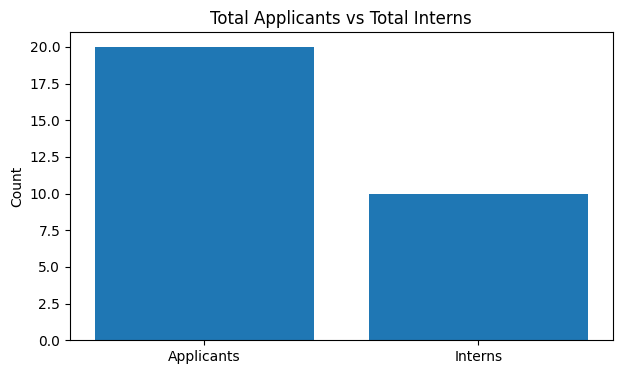

In [ ]:
import matplotlib.pyplot as plt

# Create dashboard metrics
total_applicants = len(applicants)
total_interns = len(interns)

print("===== PROGRAM PERFORMANCE DASHBOARD =====")
print("Total Applicants:", total_applicants)
print("Total Interns:", total_interns)

# Create comparison chart
plt.figure(figsize=(7, 4))

plt.bar(
    ["Applicants", "Interns"],
    [total_applicants, total_interns]
)

plt.title("Total Applicants vs Total Interns")
plt.ylabel("Count")
plt.show()

In [ ]:
# Calculate completion rate per domain

completed = interns[
    interns["completion_status"] == "Completed"
]

total_by_domain = applicants.groupby("domain").size()

completed_by_domain = completed.groupby("domain").size()

completion_rate = (
    completed_by_domain.reindex(
        total_by_domain.index, fill_value=0
    ) / total_by_domain * 100
).round(2)

print("Completion Rate per Domain:")
display(completion_rate.reset_index(name="completion_rate_pct"))

Completion Rate per Domain:


,domain,completion_rate_pct
0,App Development,25.0
1,Cyber Security,25.0
2,Data Science,50.0
3,UI/UX Design,50.0
4,Web Development,50.0


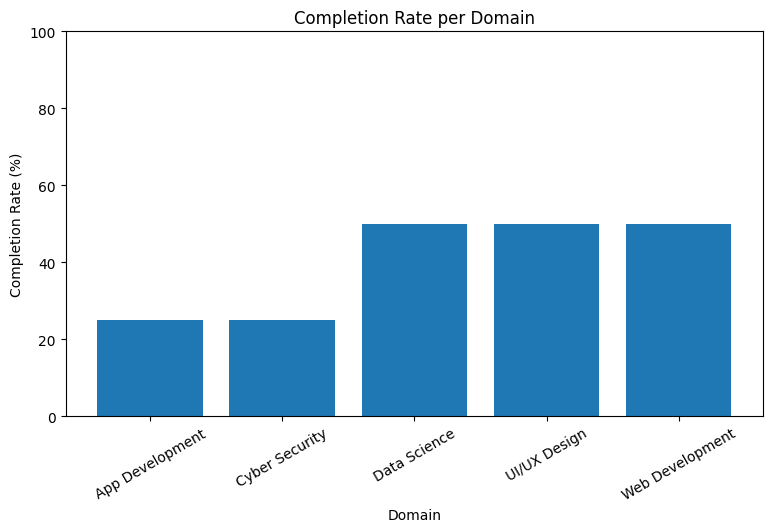

In [ ]:
# Bar chart: Completion Rate per Domain

plt.figure(figsize=(9, 5))

plt.bar(
    completion_rate.index,
    completion_rate.values
)

plt.title("Completion Rate per Domain")
plt.xlabel("Domain")
plt.ylabel("Completion Rate (%)")
plt.xticks(rotation=30)
plt.ylim(0, 100)

plt.show()

In [ ]:
# Calculate average hackathon score per domain

avg_scores = hackathon_scores.groupby("domain")["score"].mean().round(2)

print("Average Hackathon Score per Domain:")
display(avg_scores.reset_index(name="avg_score"))

Average Hackathon Score per Domain:


,domain,avg_score
0,App Development,82.0
1,Cyber Security,90.0
2,Data Science,84.0
3,UI/UX Design,87.5
4,Web Development,84.5


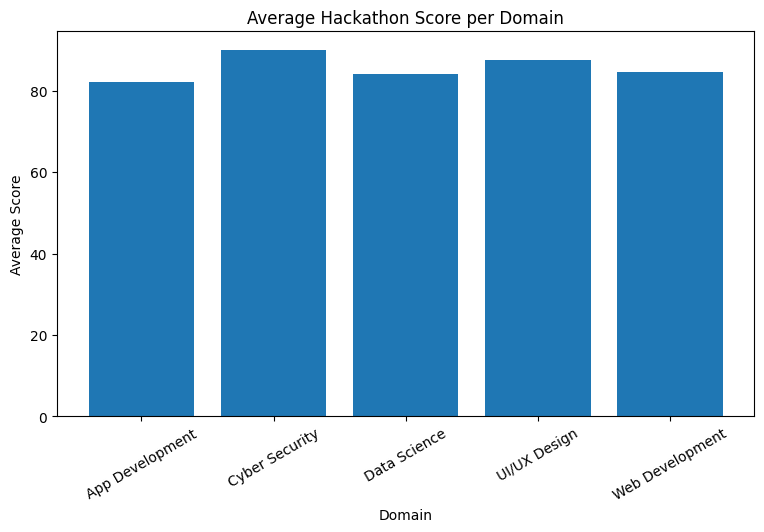

In [ ]:
# Bar chart: Average Hackathon Score per Domain

plt.figure(figsize=(9, 5))

plt.bar(
    avg_scores.index,
    avg_scores.values
)

plt.title("Average Hackathon Score per Domain")
plt.xlabel("Domain")
plt.ylabel("Average Score")
plt.xticks(rotation=30)

plt.show()

In [ ]:
# Create Top 10 Intern Leaderboard

leaderboard = pd.merge(
    interns,
    hackathon_scores,
    on=["intern_id", "domain"]
)

leaderboard = leaderboard[
    ["intern_id", "domain", "completion_status", "score"]
]

leaderboard = leaderboard.sort_values(
    by="score",
    ascending=False
).head(10)

print("TOP 10 INTERN LEADERBOARD")
display(leaderboard)

TOP 10 INTERN LEADERBOARD


,intern_id,domain,completion_status,score
2,103,Data Science,Completed,95
9,110,App Development,Completed,94
0,101,Data Science,Completed,92
6,107,Cyber Security,Completed,90
7,108,UI/UX Design,Completed,89
1,102,Web Development,Completed,88
4,105,UI/UX Design,Completed,86
5,106,Web Development,Completed,81
3,104,App Development,Dropped Out,70
8,109,Data Science,Dropped Out,65


In [ ]:
# Create domain filter

domain_options = ["All"] + sorted(
    applicants["domain"].unique().tolist()
)

print("Available Domain Filters:")
for domain in domain_options:
    print(domain)

Available Domain Filters:
All
App Development
Cyber Security
Data Science
UI/UX Design
Web Development


In [ ]:
import ipywidgets as widgets
from IPython.display import display

domain_options = ["All"] + sorted(applicants["domain"].unique().tolist())

domain_dropdown = widgets.Dropdown(
    options=domain_options,
    value="All",
    description="Select Domain:",
    style={"description_width": "initial"}
)

display(domain_dropdown)

Dropdown(description='Select Domain:', options=('All', 'App Development', 'Cyber Security', 'Data Science', 'U…

In [ ]:
def update_dashboard(domain):
    if domain == "All":
        filtered_applicants = applicants
        filtered_interns = interns
        filtered_scores = hackathon_scores
    else:
        filtered_applicants = applicants[applicants["domain"] == domain]
        filtered_interns = interns[interns["domain"] == domain]
        filtered_scores = hackathon_scores[hackathon_scores["domain"] == domain]

    total_applicants = len(filtered_applicants)
    total_interns = len(filtered_interns)

    completed_interns = len(
        filtered_interns[filtered_interns["completion_status"] == "Completed"]
    )

    completion_rate = (
        completed_interns / total_applicants * 100
        if total_applicants > 0 else 0
    )

    average_score = (
        filtered_scores["score"].mean()
        if not filtered_scores.empty else 0
    )

    print("Selected Domain:", domain)
    print("Total Applicants:", total_applicants)
    print("Total Interns:", total_interns)
    print("Completion Rate:", round(completion_rate, 2), "%")
    print("Average Hackathon Score:", round(average_score, 2))


widgets.interactive_output(
    update_dashboard,
    {"domain": domain_dropdown}
)

Output()

In [ ]:
import matplotlib.pyplot as plt

def update_completion_chart(domain):
    if domain == "All":
        filtered_applicants = applicants
        filtered_interns = interns
    else:
        filtered_applicants = applicants[applicants["domain"] == domain]
        filtered_interns = interns[interns["domain"] == domain]

    completed = filtered_interns[
        filtered_interns["completion_status"] == "Completed"
    ]

    completion_data = (
        completed.groupby("domain").size()
        / filtered_applicants.groupby("domain").size()
        * 100
    ).fillna(0)

    completion_data.plot(kind="bar", figsize=(8, 4))
    plt.title("Completion Rate by Domain")
    plt.ylabel("Completion Rate (%)")
    plt.xlabel("Domain")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


widgets.interactive_output(
    update_completion_chart,
    {"domain": domain_dropdown}
)

Output()

In [ ]:
def update_score_chart(domain):
    if domain == "All":
        filtered_scores = hackathon_scores
    else:
        filtered_scores = hackathon_scores[
            hackathon_scores["domain"] == domain
        ]

    average_scores = filtered_scores.groupby("domain")["score"].mean()

    average_scores.plot(kind="bar", figsize=(8, 4))
    plt.title("Average Hackathon Score by Domain")
    plt.ylabel("Average Score")
    plt.xlabel("Domain")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


widgets.interactive_output(
    update_score_chart,
    {"domain": domain_dropdown}
)

Output()

In [ ]:
def update_leaderboard(domain):
    leaderboard = pd.merge(
        interns,
        hackathon_scores,
        on="intern_id",
        suffixes=("_intern", "_score")
    )

    if domain != "All":
        leaderboard = leaderboard[
            leaderboard["domain_intern"] == domain
        ]

    leaderboard = leaderboard[
        ["intern_id", "domain_intern", "completion_status", "score"]
    ]

    leaderboard = leaderboard.sort_values(
        by="score", ascending=False
    ).head(10)

    leaderboard = leaderboard.rename(
        columns={"domain_intern": "domain"}
    )

    display(leaderboard)


widgets.interactive_output(
    update_leaderboard,
    {"domain": domain_dropdown}
)

Output()

In [ ]:
def show_full_dashboard(domain):
    print("=" * 45)
    print("INTERNSHIP PERFORMANCE DASHBOARD")
    print("=" * 45)

    if domain == "All":
        filtered_applicants = applicants
        filtered_interns = interns
        filtered_scores = hackathon_scores
    else:
        filtered_applicants = applicants[
            applicants["domain"] == domain
        ]
        filtered_interns = interns[
            interns["domain"] == domain
        ]
        filtered_scores = hackathon_scores[
            hackathon_scores["domain"] == domain
        ]

    completed = filtered_interns[
        filtered_interns["completion_status"] == "Completed"
    ]

    total_applicants = len(filtered_applicants)
    total_interns = len(filtered_interns)

    rate = (
        len(completed) / total_applicants * 100
        if total_applicants else 0
    )

    avg_score = (
        filtered_scores["score"].mean()
        if not filtered_scores.empty else 0
    )

    print("Domain:", domain)
    print("Total Applicants:", total_applicants)
    print("Total Interns:", total_interns)
    print("Completion Rate:", round(rate, 2), "%")
    print("Average Score:", round(avg_score, 2))

    print("\nTOP LEADERBOARD")

    leaderboard = pd.merge(
        filtered_interns,
        filtered_scores,
        on=["intern_id", "domain"],
        how="inner"
    )

    display(
        leaderboard[
            ["intern_id", "domain", "completion_status", "score"]
        ].sort_values("score", ascending=False).head(10)
    )


widgets.interactive_output(
    show_full_dashboard,
    {"domain": domain_dropdown}
)

Output()

In [ ]:
print("Applicants:", "applicants" in globals())
print("Interns:", "interns" in globals())
print("Hackathon Scores:", "hackathon_scores" in globals())

Applicants: True
Interns: True
Hackathon Scores: True


In [ ]:
import sqlite3

conn = sqlite3.connect("nextgen.db")

applicants.to_sql("applicants", conn, if_exists="replace", index=False)
interns.to_sql("interns", conn, if_exists="replace", index=False)
hackathon_scores.to_sql("hackathon_scores", conn, if_exists="replace", index=False)

conn.close()

print("Database created successfully!")

Database created successfully!


In [ ]:

%%writefile dashboard.py

import streamlit as st
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="Internship Performance Dashboard",
    layout="wide"
)

conn = sqlite3.connect("nextgen.db")

applicants = pd.read_sql("SELECT * FROM applicants", conn)
interns = pd.read_sql("SELECT * FROM interns", conn)
hackathon_scores = pd.read_sql("SELECT * FROM hackathon_scores", conn)

conn.close()

st.title("Internship Performance Dashboard")
st.write("Program Performance Overview")

domains = ["All"] + sorted(applicants["domain"].unique().tolist())

selected_domain = st.selectbox("Select Domain", domains)

if selected_domain == "All":
    filtered_applicants = applicants
    filtered_interns = interns
    filtered_scores = hackathon_scores
else:
    filtered_applicants = applicants[applicants["domain"] == selected_domain]
    filtered_interns = interns[interns["domain"] == selected_domain]
    filtered_scores = hackathon_scores[hackathon_scores["domain"] == selected_domain]

total_applicants = len(filtered_applicants)
total_interns = len(filtered_interns)

completed = filtered_interns[
    filtered_interns["completion_status"] == "Completed"
]

completion_rate = (
    len(completed) / total_applicants * 100
    if total_applicants > 0 else 0
)

average_score = (
    filtered_scores["score"].mean()
    if not filtered_scores.empty else 0
)

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Applicants", total_applicants)
col2.metric("Total Interns", total_interns)
col3.metric("Completion Rate", f"{completion_rate:.1f}%")
col4.metric("Average Score", f"{average_score:.1f}")

st.subheader("Completion Rate by Domain")

completion_data = (
    interns[interns["completion_status"] == "Completed"]
    .groupby("domain").size()
    / applicants.groupby("domain").size()
    * 100
).fillna(0)

if selected_domain == "All":
    st.bar_chart(completion_data)
else:
    st.bar_chart(completion_data.reindex([selected_domain]).dropna())

st.subheader("Average Hackathon Score by Domain")

score_data = hackathon_scores.groupby("domain")["score"].mean()

if selected_domain == "All":
    st.bar_chart(score_data)
else:
    st.bar_chart(score_data.reindex([selected_domain]).dropna())

st.subheader("Top 10 Leaderboard")

leaderboard = pd.merge(
    filtered_interns,
    filtered_scores,
    on=["intern_id", "domain"],
    how="inner"
)

leaderboard = leaderboard[
    ["intern_id", "domain", "completion_status", "score"]
].sort_values("score", ascending=False).head(10)

st.dataframe(leaderboard, use_container_width=True)

Overwriting dashboard.py


Day 5 — Program Performance Dashboard Development

Objective

The objective of Day 5 was to develop an interactive dashboard to visualize internship program performance using Streamlit.

Dashboard Development

I created an interactive dashboard using Python, Pandas, SQLite, and Streamlit. The dashboard reads data from the SQLite database "nextgen.db", which contains three tables: applicants, interns, and hackathon_scores.

The dashboard includes the following features:

1. Total Applicants: Displays the total number of applicants.
2. Total Interns: Displays the total number of interns.
3. Completion Rate: Shows the percentage of applicants who completed the internship.
4. Average Hackathon Score: Displays the average score of interns.
5. Completion Rate by Domain: A bar chart showing internship completion rates across different domains.
6. Average Hackathon Score by Domain: A bar chart comparing average hackathon scores across domains.
7. Top 10 Leaderboard: Displays interns ranked by their hackathon scores.

Interactive Domain Filter

I added a domain selection dropdown to the dashboard. Users can select "All" or a specific domain, such as Data Science, Web Development, Cyber Security, App Development, or UI/UX Design.

When a domain is selected, the dashboard updates the displayed metrics, charts, and leaderboard according to the selected domain.

Dashboard Testing

I tested the dashboard using different domain selections. The dashboard successfully loaded the database records and displayed the corresponding metrics and charts.

I also captured screenshots of the dashboard showing the default view and domain-filtered views as demonstration evidence.

Deployment

I uploaded the dashboard source code and SQLite database to my GitHub repository and deployed the application using Streamlit Community Cloud.

The deployed dashboard was tested to confirm that the application loads, data is displayed, and the domain filter updates the dashboard.

Conclusion

In Day 5, I completed the interactive internship performance dashboard. This task helped me practice data visualization, database integration, dashboard development, and deployment using Streamlit.

The dashboard provides a simple way to explore internship program performance and compare results across different domains.